<a href="https://colab.research.google.com/github/batrisyiasuh/batrisyia5842342-AnalyticsEngineering/blob/main/Analytics%20in%20Practice%20WS7%20Exercise.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Workshop 7a · Exercise

**Author:** Nursen Aydin

Now it is your turn. A bank wants to predict which credit card customers will **default** (fail to repay) next year. You clean and prepare its customer data, following Demo 1 and Demo 2. Most tasks are similar to the demos, so keep them open next to this notebook. Some tasks go one step further, so read each task carefully.

The file **Credit_raw.csv** describes 400 credit card customers:

| Column | Meaning |
|---|---|
| No | Customer number |
| Income | Annual income (in $1,000s) |
| Limit | Credit limit |
| Rating | Credit rating |
| Cards | Number of credit cards |
| Age | Age in years |
| Education | Years of education |
| Gender, Student, Married | Customer details |
| Balance | Average credit card balance |
| **Default** | **Target:** did the customer default in the following year? (Yes/No)

*Analytics problem:* at the start of each year, predict for every current credit card customer whether they will default during the following year (`Default` = Yes or No), using the information the bank has about them at that moment. Because the answer is a category, this is a *classification* problem.

**Before you start:** put `Credit_raw.csv` in the same folder as this notebook. *Using Google Colab?* Upload it with the folder icon on the left.

Replace every `---` with your code. Write short answers to the questions in the markdown cells for your study.

In [19]:
# Removed incorrect drive mount that created a directory named 'Credit_raw.csv'
# Please upload your 'Credit_raw.csv' dataset using the folder icon on the left panel.

-----
# Part 1: Cleaning, splitting and missing values

-----
## 1. Load the data and take a first look

**Task 1.** Import **pandas**, **NumPy** and **Matplotlib**. Load `Credit_raw.csv` with the same `read_csv()` settings as Demo 1, so that only empty cells and `NA` count as missing. Then show the number of rows and columns, the first four rows, and the structure.

In [20]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split

crdata = pd.read_csv('Credit_raw.csv')

# Check the number of rows and columns
print(crdata.shape)

# Check the first four rows using .head() function
print(crdata.head(4))

# Check the structure
crdata.info()

(400, 12)
   No   Income   Limit  Rating  Cards   Age  Education  Gender Student  \
0   1   14.891  3606.0   283.0      2  34.0       11.0    Male      No   
1   2      NaN  6645.0   483.0      3  82.0       15.0  Female     Yes   
2   3  104.593  7075.0   514.0      4  71.0       11.0    Male      No   
3   4  148.924  9504.0   681.0      3  36.0       11.0  Female      No   

  Married  Balance Default  
0     Yes      333      No  
1     Yes      903      No  
2      No      580      No  
3      No      964      No  
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 400 entries, 0 to 399
Data columns (total 12 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   No         400 non-null    int64  
 1   Income     340 non-null    float64
 2   Limit      398 non-null    float64
 3   Rating     399 non-null    float64
 4   Cards      400 non-null    int64  
 5   Age        399 non-null    float64
 6   Education  399 non-null    float64
 7   Gend

**Question:** which column is an identifier, not a quantity?

Note that an **identifier** is a column that only labels each row (like a customer number). It tells us *which* row it is, but it is not a quantity.

*Your answer:* The **No** column is the identifier because it just lists the row numbers (customer IDs) and does not represent any measurable quantity.

-----
## 2. Remove columns that carry no information

**Task 2.** Remove the columns that you think do not carry any meaningful information. Then check the number of rows and columns.

In [21]:
# Remove the column(s) that carry no information
crdata = crdata.drop(columns=['No'])
print(crdata.shape)

(400, 11)


-----
## 3. Category labels

At the end of the label section in Demo 1, we noted other label problems you may meet, such as **stray spaces** (fixed with `.str.strip()`) and **different capitalisation** (fixed with `.str.title()` or `.str.lower()`).

**Task 3.** Check the labels of the categorical (text) columns.

*Careful:* a label with a space at the end looks exactly like one without it. If you see the same label twice, a hidden space is the reason.

In [22]:
# Hint: a list of the text column names, e.g. ["A", "B"]; use .info() to see which columns are text
for column in ['Gender', 'Student', 'Married', 'Default']:
    print(crdata[column].value_counts(), "\n")

Gender
Female     205
Male       192
female       1
MALE         1
 Female      1
Name: count, dtype: int64 

Student
No      359
Yes      38
yes       1
YES       1
Name: count, dtype: int64 

Married
Yes    243
No     152
no       1
No       1
Name: count, dtype: int64 

Default
No     349
Yes     51
Name: count, dtype: int64 



Now fix all of them in one go: `.str.strip()` removes the spaces, then `.str.title()` makes the first letter a capital and the rest lower case. Then check again.

In [23]:
# Fix the labels: remove spaces, then use the same capitalisation
for column in ["Gender", "Student", "Married", "Default"]:
    crdata[column] = crdata[column].str.strip().str.title()

# Check again
for column in ["Gender", "Student", "Married", "Default"]:
    print(crdata[column].value_counts(), "\n")

Gender
Female    207
Male      193
Name: count, dtype: int64 

Student
No     359
Yes     40
Name: count, dtype: int64 

Married
Yes    243
No     154
Name: count, dtype: int64 

Default
No     349
Yes     51
Name: count, dtype: int64 



-----
## 4. Split the data first

So far we have only applied **fixed rules** (remove a column, fix spelling). From now on, some steps learn from the data: for example, we fill gaps with the median. The test set stands in for future customers the model has never seen, so it must not help to calculate these values. Otherwise the test result looks better than it should (this is called **data leakage**).

So we split now, as in Demo 2. This time we split the whole table into a *training set* and a *test set*, and keep the target inside each:

```python
train, test = train_test_split(data, test_size=0.2, random_state=123, stratify=data["Default"])
```

**Rule for the rest of the exercise:** we **look and learn** on the training set only, and **apply the same rule** to both sets.

**Task 4.** Split `crdata` into `train` (80%) and `test` (20%), stratified by the target variable. Check the number of rows and the share of defaults in each set.

In [24]:
train, test = train_test_split(crdata, test_size=0.2, random_state=123, stratify=crdata["Default"])

print("Training set:", train.shape[0], "rows; test set:", test.shape[0], "rows")
print("\nShare of defaults in all data:\n", crdata["Default"].value_counts(normalize=True).round(3))
print("\nTraining set:\n", train["Default"].value_counts(normalize=True).round(3))
print("\nTest set:\n", test["Default"].value_counts(normalize=True).round(3))

Training set: 320 rows; test set: 80 rows

Share of defaults in all data:
 Default
No     0.872
Yes    0.128
Name: proportion, dtype: float64

Training set:
 Default
No     0.872
Yes    0.128
Name: proportion, dtype: float64

Test set:
 Default
No     0.875
Yes    0.125
Name: proportion, dtype: float64


-----
## 5. Implausible values

**Task 5.** Look at the summary statistics of the **training set**. Which column has an implausible value?

In [25]:
train.describe()

,Income,Limit,Rating,Cards,Age,Education,Balance
count,277.000000,318.000000,319.000000,320.000000,319.000000,319.000000,320.000000
mean,45.359011,4699.638365,352.125392,3.015625,57.473354,13.391850,505.568750
std,36.556750,2332.852607,155.912177,1.401882,30.107121,3.109136,452.775081
min,10.354000,855.000000,93.000000,1.000000,23.000000,5.000000,0.000000
25%,20.088000,3077.500000,248.500000,2.000000,44.000000,11.000000,52.000000
50%,32.856000,4497.000000,339.000000,3.000000,56.000000,14.000000,430.000000
75%,58.026000,5766.500000,432.000000,4.000000,70.000000,16.000000,844.500000
max,182.728000,13913.000000,982.000000,9.000000,500.000000,19.000000,1999.000000


Let's look at **Age** with a box plot. Note that `plt.boxplot` cannot calculate anything from a column that contains NaN: it draws an empty chart, without an error message. So we remove the missing values with `.dropna()` before plotting.

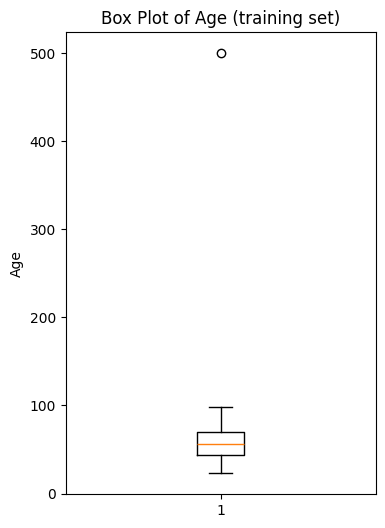

In [26]:
plt.figure(figsize=(4, 6))
# Hint: df["column"].dropna() removes the missing values before plotting
plt.boxplot(train["Age"].dropna())
plt.title("Box Plot of Age (training set)")
plt.ylabel("Age")
plt.show()

In [27]:
# Show the customers with age 100 or higher in the training set
print(train[train["Age"] >= 100])

     Income   Limit  Rating  Cards    Age  Education Gender Student Married  \
129  18.145  3461.0   279.0      3  500.0       15.0   Male      No     Yes   

     Balance Default  
129      255      No  


A customer in the training set has an age of exactly **500**. In Demo 1 we kept Pulse 40. Is Age 500 the same kind of case?

**Task 6.** Decide what to do with ages of 500. Here are some options:

- Keep them as they are. No code needed.
- Delete these customers. First get their row numbers: `row_numbers = train.loc[train["Age"] == 500].index`. Then remove those rows with `.drop(index=row_numbers)`.
- Set their age to missing (and fill it later). Use `.replace()`, as for the labels: `train["Age"] = train["Age"].replace(---, np.nan)`

Whatever you decide is a **rule**, so apply it to **both** sets. Then check how many ages of 500 each set had.

*My decision and reason:* We should replace the age of 500 with **NaN** (missing value) because a human age of 500 is physically impossible and must be a typing mistake. Replacing it with NaN lets us estimate a realistic age for these customers later.

Ages of 500 in training set: 1
Ages of 500 in test set:     2

Training set: 320 customers, 2 missing ages
Test set:     80 customers, 2 missing ages


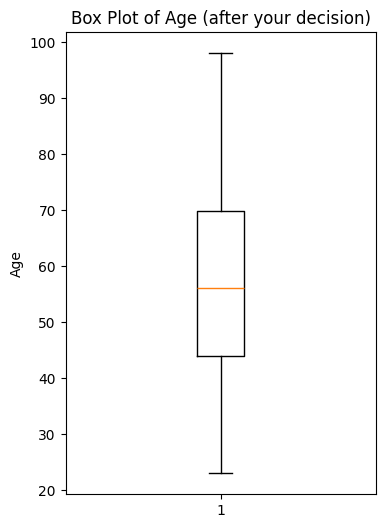

In [28]:
# Count the ages of 500 in each set before applying your rule
print("Ages of 500 in training set:", (train["Age"] == 500).sum())
print("Ages of 500 in test set:    ", (test["Age"] == 500).sum())

# Your rule for the ages of 500: apply it to the training set AND the test set
train["Age"] = train["Age"].replace(500, np.nan)
test["Age"] = test["Age"].replace(500, np.nan)

# Check the result of your decision
print("\nTraining set:", train.shape[0], "customers,", train["Age"].isnull().sum(), "missing ages")
print("Test set:    ", test.shape[0], "customers,", test["Age"].isnull().sum(), "missing ages")

plt.figure(figsize=(4, 6))
plt.boxplot(train["Age"].dropna())
plt.title("Box Plot of Age (after your decision)")
plt.ylabel("Age")
plt.show()

**Question:** how many customers in the training set have a **Balance of exactly 0**? Is that an error, or a real situation? Should we change it?

*Your answer:* There are **74** customers with a balance of exactly 0. This is a real-life situation because many people have credit cards but do not use them or have fully paid off their outstanding balance. We should **not** change it.

In [29]:
# Hint: (df["column"] == 0) is True for zeros; .sum() counts them
print((train["Balance"] == 0).sum())

74


*Your answer:*

-----
## 6. Missing values

**Task 7.** Count the missing values in each column of both sets, and their proportion (%) in the training set.

In [30]:
# You can use .isnull() and .sum() functions together
print("Training set:\n", train.isnull().sum())
print("\nTest set:\n", test.isnull().sum())

# number missing / number of rows * 100
print("\nTraining set (%):\n", (train.isnull().sum() / len(train) * 100).round(1))

Training set:
 Income       43
Limit         2
Rating        1
Cards         0
Age           2
Education     1
Gender        0
Student       1
Married       3
Balance       0
Default       0
dtype: int64

Test set:
 Income       17
Limit         0
Rating        0
Cards         0
Age           2
Education     0
Gender        0
Student       0
Married       0
Balance       0
Default       0
dtype: int64

Training set (%):
 Income       13.4
Limit         0.6
Rating        0.3
Cards         0.0
Age           0.6
Education     0.3
Gender        0.0
Student       0.3
Married       0.9
Balance       0.0
Default       0.0
dtype: float64


**Task 8 (option A).** How many training customers would we lose if we deleted every row with a missing value?

In [31]:
# Note that .dropna() removes every row with at least one missing value
train_dropped = train.dropna()

# Note that .shape[0] gives the number of rows
rows_removed = train.shape[0] - train_dropped.shape[0]

print(f"Rows removed: {rows_removed} of {train.shape[0]} ({rows_removed / train.shape[0]:.0%})")

Rows removed: 53 of 320 (17%)


**Task 9 (option B).** Instead, fill the gaps. Remember the rule: **learn** the fill values on the training set, **apply** them to both sets.
- First keep a copy of the training Income as it is now (we need it in Task 10).
- Add two new columns, `Income_missing` and `Age_missing`, as missing flags: **1** where the value is missing, **0** where it was observed. Do this *before* filling, otherwise the gaps are gone.
- Fill the numerical columns with the **median of the training set**.
- Fill Student with the most frequent category (the *mode*) of the training set.
- Fill Married with a new category, *"Unknown"*, instead of guessing. Demo 1 described this option: an explicit category for missing answers, useful when the gap itself may carry information.

In [32]:
# Keep a copy of the training Income before filling (for Task 10)
income_before = train["Income"].copy()

# Missing flags in both sets (before filling!)
# Hint: df["column"].isnull().astype(int) gives 1 where missing, 0 otherwise
train["Income_missing"] = train["Income"].isnull().astype(int)
test["Income_missing"] = test["Income"].isnull().astype(int)
train["Age_missing"] = train["Age"].isnull().astype(int)
test["Age_missing"] = test["Age"].isnull().astype(int)

# Median fill: the median is learned from the TRAINING set and used for both sets
numeric_columns = train.select_dtypes(include="number").columns
print(numeric_columns)

for column in numeric_columns:
    median = train[column].median()
    train[column] = train[column].fillna(median)
    test[column] = test[column].fillna(median)

# Student: the mode of the TRAINING set, used for both sets
# Hint: .mode()[0] gives the most frequent category
most_frequent = train["Student"].mode()[0]
train["Student"] = train["Student"].fillna(most_frequent)
test["Student"] = test["Student"].fillna(most_frequent)

# Married: a new category "Unknown" in both sets
train["Married"] = train["Married"].fillna("Unknown")
test["Married"] = test["Married"].fillna("Unknown")

# Check: no missing values left
print("\nTraining set:", train.isnull().sum().sum(), "missing values left")
print("Test set:    ", test.isnull().sum().sum(), "missing values left")

Index(['Income', 'Limit', 'Rating', 'Cards', 'Age', 'Education', 'Balance',
       'Income_missing', 'Age_missing'],
      dtype='object')

Training set: 0 missing values left
Test set:     0 missing values left


**Question:** the test set has 17 missing incomes. Why do we fill them with the median of the **training** set, not the median of the test set?

*Your answer:* We use the training set's median to prevent **data leakage**. In real life, the test set represents future customers whose overall statistics we would not know yet. The model must rely only on what it learned from the training data.

-----
## 7. What did filling do?

Filling keeps every customer. But does it change the data?

**Task 10.** Compare the training Income *before* and *after* filling: the summary statistics, and a histogram of each.

Before filling:
count    277.0
mean      45.4
std       36.6
min       10.4
25%       20.1
50%       32.9
75%       58.0
max      182.7
Name: Income, dtype: float64

After filling:
count    320.0
mean      43.7
std       34.3
min       10.4
25%       21.0
50%       32.9
75%       54.4
max      182.7
Name: Income, dtype: float64


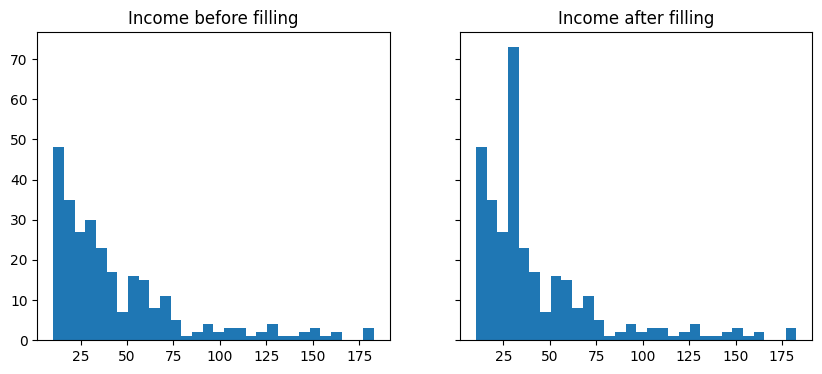

In [33]:
# Summary statistics before and after
print("Before filling:")
print(income_before.describe().round(1))

print("\nAfter filling:")
print(train["Income"].describe().round(1))

# Histograms side by side
fig, axes = plt.subplots(1, 2, figsize=(10, 4), sharey=True)
# Hint: .dropna() removes the missing values before plotting
axes[0].hist(income_before.dropna(), bins=30)
axes[0].set_title("Income before filling")

axes[1].hist(train["Income"], bins=30)
axes[1].set_title("Income after filling")
plt.show()

**What happened?**
- **count** went from 277 to 320: we kept every training customer.
- The **median** did not change, and the **mean** moved only a little.
- The **standard deviation** went down: the incomes now look less spread out than they really are.
- The histogram has a tall **spike** at the median: 43 customers now have exactly the same income.

**Main lesson:** filling keeps the rows, but the filled values are **guesses, not data**. Filling with one value makes the data look more uniform, and more certain, than they really are.

**Be aware:**
- **The more you fill, the bigger the effect.** Two filled ages hardly matter. Forty-three filled incomes (13%) visibly change the column.
- **Relationships get weaker.** Customers with very different credit limits now share the same income, so Income and Limit look less related than they are.
- **If the gaps are not random**, the median can be a poor guess. For example, if high earners were the ones who did not share their income, filling with the median makes everyone look poorer.
- **Keep the missing flag and record the number of filled values** in your log, so anyone using the data knows which values were guesses.

-----
# Part 2: Encoding, balancing and saving

If you continue at home, open this notebook and run all cells of Part 1 first (**Kernel → Restart & Run All**), then carry on here.

-----
## 8. Encoding

**Task 11.** Encode the text columns in **both** sets:
- **Gender**, **Student** and the target **Default** have two values each. Use `np.where()`.
- **Married** has three values: Yes, No and **Unknown**. There is no order, so we use one-hot encoding with `pd.get_dummies()`, as in Demo 2.

First, look at Married in each set:

In [16]:
print("Training set:\n", train["Married"].value_counts())
print("\nTest set:\n", test["Married"].value_counts())

Training set:
 Married
Yes        194
No         123
Unknown      3
Name: count, dtype: int64

Test set:
 Married
Yes    49
No     31
Name: count, dtype: int64


**Question:** depending on the random split, a category such as "Unknown" may appear in the training set but not in the test set (or the other way round). What would go wrong if we used `pd.get_dummies()` on each set without fixing the list of categories?

*Your answer:* The training set and test set would end up with a different number of columns. This would crash the machine learning model because a model needs the exact same features (columns) for both training and making predictions.

To avoid this, we first tell pandas the **full list** of Married categories with `pd.Categorical()`. Then `pd.get_dummies()` creates a column for every category in the list, even if it does not appear in one of the sets (that column is then all 0). This is the same idea as `astype("category")` in Demo 1, but with the list of categories written out.

With `drop_first=True`, the first category in our list ("No") is dropped. After one-hot encoding, a customer with 0 in both `Married_Yes` and `Married_Unknown` is not married.

In [34]:
# Binary columns: the same rule in both sets
for data in [train, test]:
    data["Gender"] = np.where(data["Gender"] == "Female", 1, 0)
    data["Student"] = np.where(data["Student"] == "Yes", 1, 0)
    data["Default"] = np.where(data["Default"] == "Yes", 1, 0)

# Married: fix the list of categories in both sets
for data in [train, test]:
    data["Married"] = pd.Categorical(data["Married"], categories=["No", "Yes", "Unknown"])

# One-hot encoding: both sets now always get the same columns
# Hint: pd.get_dummies(data, columns=["column"], drop_first=True, dtype=int)
train = pd.get_dummies(train, columns=["Married"], drop_first=True, dtype=int)
test = pd.get_dummies(test, columns=["Married"], drop_first=True, dtype=int)

# Check: same columns in both sets?
print(train.columns.tolist() == test.columns.tolist())
train.head()

True


,Income,Limit,Rating,Cards,Age,Education,Gender,Student,Balance,Default,Income_missing,Age_missing,Married_Yes,Married_Unknown
184,158.889,11589.0,805.0,1,62.0,17.0,1,0,1448,0,0,0,1,0
281,36.142,1852.0,183.0,3,33.0,13.0,1,0,0,0,0,0,0,0
241,15.602,906.0,103.0,2,65.0,11.0,0,0,0,0,0,0,1,0
84,32.856,2906.0,232.0,4,69.0,11.0,0,0,0,0,1,0,0,0
21,37.348,6378.0,458.0,1,72.0,17.0,1,0,968,0,0,0,0,0


*Note:* `for data in [train, test]:` repeats the same lines for the training set and the test set, so the rule is written once and applied to both.

-----
## 9. Balancing the training set

Only about 13% of the customers default. Compare two ways to balance the **training set** to 50% defaults:
- **Oversampling** (`RandomOverSampler`): copy default rows until there are as many defaults as non-defaults.
- **Undersampling** (`RandomUnderSampler`): randomly **remove** non-default rows until there are as many non-defaults as defaults.

**Task 12.** Separate the features and the target in each set. Then apply both methods to the training set with `sampling_strategy=1.0` and `random_state=1`, and count the rows in each result.

In [35]:
from imblearn.over_sampling import RandomOverSampler
from imblearn.under_sampling import RandomUnderSampler

# Features and target
X_train = train.drop(columns=["Default"])
y_train = train["Default"]
X_test = test.drop(columns=["Default"])
y_test = test["Default"]

# Oversampling
oversampler = RandomOverSampler(sampling_strategy=1.0, random_state=1)
X_over, y_over = oversampler.fit_resample(X_train, y_train)

# Undersampling
undersampler = RandomUnderSampler(sampling_strategy=1.0, random_state=1)
X_under, y_under = undersampler.fit_resample(X_train, y_train)

print("Original training set:", len(y_train), "rows")
print(y_train.value_counts(), "\n")
print("After oversampling:", len(y_over), "rows")
print(y_over.value_counts(), "\n")
print("After undersampling:", len(y_under), "rows")
print(y_under.value_counts())

Original training set: 320 rows
Default
0    279
1     41
Name: count, dtype: int64 

After oversampling: 558 rows
Default
0    279
1    279
Name: count, dtype: int64 

After undersampling: 82 rows
Default
0    41
1    41
Name: count, dtype: int64


**Question:** what does each method cost? Look at the number of rows, and think about what the rows contain.

*Your answer:*
- **Oversampling** increases the training set to 558 rows by repeating the default cases. The cost is slower training time and a risk of overfitting because the model memorizes repeated rows.
- **Undersampling** shrinks the training set to only 82 rows by throwing away non-default cases. The cost is losing a massive amount of valuable information from the deleted rows.

**Question:** we never balance the test set. Why?

*Your answer:* The test set must represent the real world. In the real world, defaults are rare (only 13%). If we balance the test set to 50/50, our test results will be unrealistic and will not show how the model will actually perform on real future customers.

-----
## 10. Save the prepared data

Save the cleaned and encoded training and test sets as new CSV files. We save them **before** balancing: balancing is part of building a model, and we may want to try different ratios later. Never overwrite the raw file: you may need to go back to it.

*Why `index=False`?* Without it, pandas also writes the row numbers as an extra first column. That is exactly where the `Unnamed: 0` column in Demo 1 came from!

**Task 13.** Save `train` as `Credit_train.csv` and `test` as `Credit_test.csv`, then load one of them again to check.

In [36]:
# Save the prepared data (without the row numbers)
# Hint: .to_csv("file name.csv", index=False)
train.to_csv("Credit_train.csv", index=False)
test.to_csv("Credit_test.csv", index=False)

# Load one again to check
check = pd.read_csv("Credit_train.csv")
print(check.shape)
check.head()

(320, 14)


,Income,Limit,Rating,Cards,Age,Education,Gender,Student,Balance,Default,Income_missing,Age_missing,Married_Yes,Married_Unknown
0,158.889,11589.0,805.0,1,62.0,17.0,1,0,1448,0,0,0,1,0
1,36.142,1852.0,183.0,3,33.0,13.0,1,0,0,0,0,0,0,0
2,15.602,906.0,103.0,2,65.0,11.0,0,0,0,0,0,0,1,0
3,32.856,2906.0,232.0,4,69.0,11.0,0,0,0,0,1,0,0,0
4,37.348,6378.0,458.0,1,72.0,17.0,1,0,968,0,0,0,0,0


*Using Google Colab?* The files are saved in Colab's temporary storage. Download them from the folder panel on the left (right-click a file, then **Download**) before you close the notebook.

-----
## 11. Your log

**Task 14.** Complete the log (double-click this cell to edit). Every change needs a reason.

| Step | What I did | Why | Rows affected |
|---|---|---|---|
| ID column | | | |
| Labels | | | |
| Splitting | | | |
| Age = 500 | | | |
| Balance = 0 | | | |
| Missing numbers | | | |
| Missing categories | | | |
| Encoding | | | |
| Balancing | | | |
| Saving | | | |

-----
## Extra: check an AI assistant's code

Below is an example of cleaning code that an AI assistant might write for this file.

1. **Run it.** Does it run without errors?
2. Run the check cell below it and compare with your own cleaned data.
3. Read each block and decide: **accept**, **reject** or **fix**, and why. Use your log: you made each of these decisions yourself today.

In [ ]:
# Block 1: Load the data
ai_data = pd.read_csv("Credit_raw.csv")

# Block 2: Remove the customer number column
ai_data = ai_data.drop(columns=["No"])

# Block 3: Clean the text labels (remove spaces, consistent capitals)
for column in ["Gender", "Student", "Married"]:
    ai_data[column] = ai_data[column].str.strip().str.title()

# Block 4: Fill missing incomes with the average income
ai_data["Income"] = ai_data["Income"].fillna(ai_data["Income"].mean())

# Block 5: Fill missing ages with the average age
ai_data["Age"] = ai_data["Age"].fillna(ai_data["Age"].mean())

# Block 6: Remove any rows that still have missing values
ai_data = ai_data.dropna()

# Block 7: Remove invalid records with a zero balance
ai_data = ai_data[ai_data["Balance"] > 0]

# Block 8: Remove income outliers (values far from the middle 50% of incomes)
q1 = ai_data["Income"].quantile(0.25)
q3 = ai_data["Income"].quantile(0.75)
iqr = q3 - q1
ai_data = ai_data[(ai_data["Income"] >= q1 - 1.5 * iqr) & (ai_data["Income"] <= q3 + 1.5 * iqr)]

# Block 9: Store the text columns as categories
ai_data[["Gender", "Student", "Married"]] = ai_data[["Gender", "Student", "Married"]].astype("category")

In [ ]:
# Compare with your own data
print("Your data (training + test):", train.shape[0] + test.shape[0], "customers")
print("AI version:                 ", ai_data.shape[0], "customers")
print("Highest age in the AI version:", ai_data["Age"].max())

| Block | What it does | Accept / Reject / Fix | Why |
|---|---|---|---|
| 1 | Load the data | | |
| 2 | Remove the customer number | | |
| 3 | Clean the text labels | | |
| 4 | Fill Income with the average | | |
| 5 | Fill Age with the average | | |
| 6 | Remove rows with missing values | | |
| 7 | Remove zero balances | | |
| 8 | Remove income outliers | | |
| 9 | Store text columns as categories | | |
| – | What is missing from this code? | | |